In [1]:
from google.colab import files

In [2]:
uploaded=files.upload()

Saving merged.zip to merged.zip


In [5]:
import os
import zipfile

zip_path = "/content/merged.zip"  # Change if your ZIP has a different name
extract_path = "/content/merged"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")
print(os.listdir(extract_path))

Dataset extracted!
['merged']


In [6]:
import os

for root, dirs, files in os.walk("/content/merged"):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))

/content/merged
Folders: ['merged']
Number of files: 0
/content/merged/merged
Folders: ['oily', 'dry', 'combination', 'normal']
Number of files: 0
/content/merged/merged/oily
Folders: []
Number of files: 957
/content/merged/merged/dry
Folders: []
Number of files: 971
/content/merged/merged/combination
Folders: []
Number of files: 341
/content/merged/merged/normal
Folders: []
Number of files: 957


In [7]:
import os
import pandas as pd

DATASET_PATH = "/content/merged/merged"

class_names = ["oily", "normal", "combination", "dry"]

image_paths = []
labels = []

for label, class_name in enumerate(class_names):
    class_folder = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(class_folder):
        file_path = os.path.join(class_folder, filename)

        if os.path.isfile(file_path):
            image_paths.append(file_path)
            labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Total images:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

print("\nClass mapping:")
for i, name in enumerate(class_names):
    print(i, "=", name)

df.head()

Total images: 3226

Class distribution:
label
0    957
1    957
2    341
3    971
Name: count, dtype: int64

Class mapping:
0 = oily
1 = normal
2 = combination
3 = dry


,image_path,label
0,/content/merged/merged/oily/oily05.jpg,0
1,/content/merged/merged/oily/oily_new_cfc0c3668...,0
2,/content/merged/merged/oily/oily_63df3d8e78556...,0
3,/content/merged/merged/oily/oily_5efdc7cd8b31c...,0
4,/content/merged/merged/oily/oily_afd41f38d6155...,0


In [8]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 2258
Validation: 484
Test: 484


In [31]:
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets created.")

Datasets created.


Image batch shape: (16, 128, 128, 3)
Label batch shape: (16,)


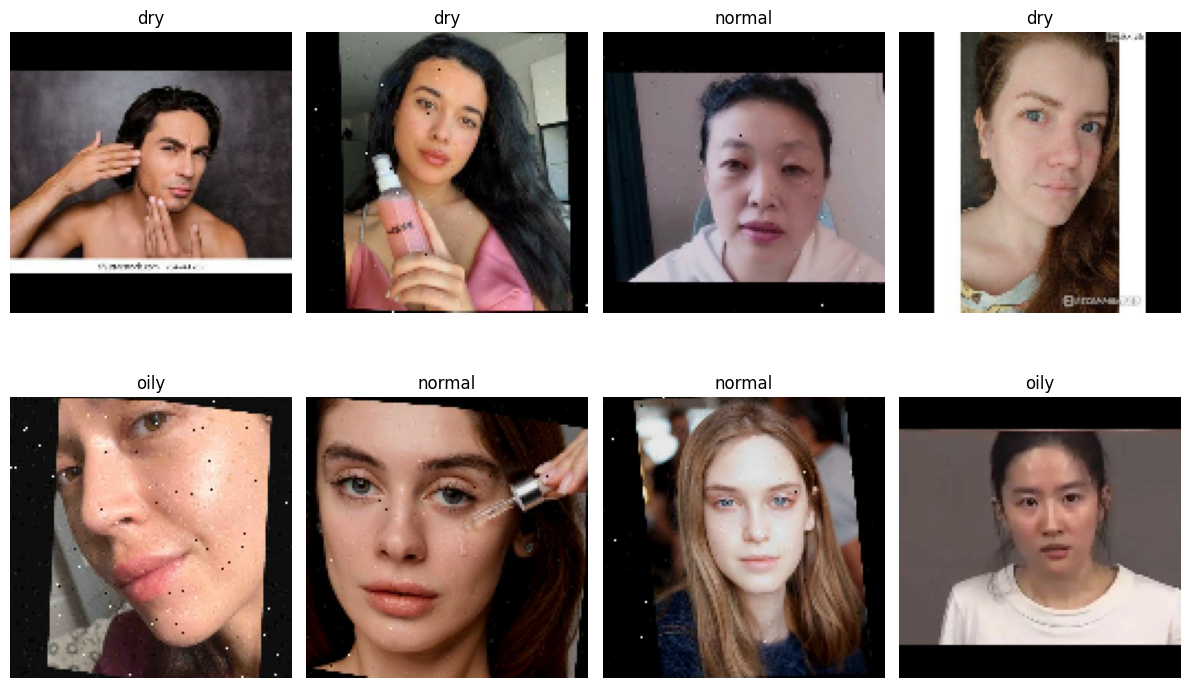

In [16]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()

model = models.Sequential([
    layers.Input(shape=(128,128, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classifier
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(4, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [34]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.8425373134328358, 1: 0.8425373134328358, 2: 2.3619246861924688, 3: 0.8313696612665685}


In [35]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_skin_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.2753 - loss: 1.6278
Epoch 1: val_loss improved from None to 1.70611, saving model to best_skin_cnn.keras

Epoch 1: finished saving model to best_skin_cnn.keras
142/142 ━━━━━━━━━━━━━━━━━━━━ 17s 76ms/step - accuracy: 0.2883 - loss: 1.5056 - val_accuracy: 0.3388 - val_loss: 1.7061 - learning_rate: 0.0010
Epoch 2/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3494 - loss: 1.3315
Epoch 2: val_loss did not improve from 1.70611
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.3313 - loss: 1.3503 - val_accuracy: 0.3099 - val_loss: 1.7569 - learning_rate: 0.0010
Epoch 3/50
141/142 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3431 - loss: 1.3337
Epoch 3: val_loss improved from 1.70611 to 1.54193, saving model to best_skin_cnn.keras

Epoch 3: finished saving model to best_skin_cnn.keras
142/142 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.3304 - loss: 1.3413 - val_accuracy: 0.2438 - val_loss: 1.5419 - lear

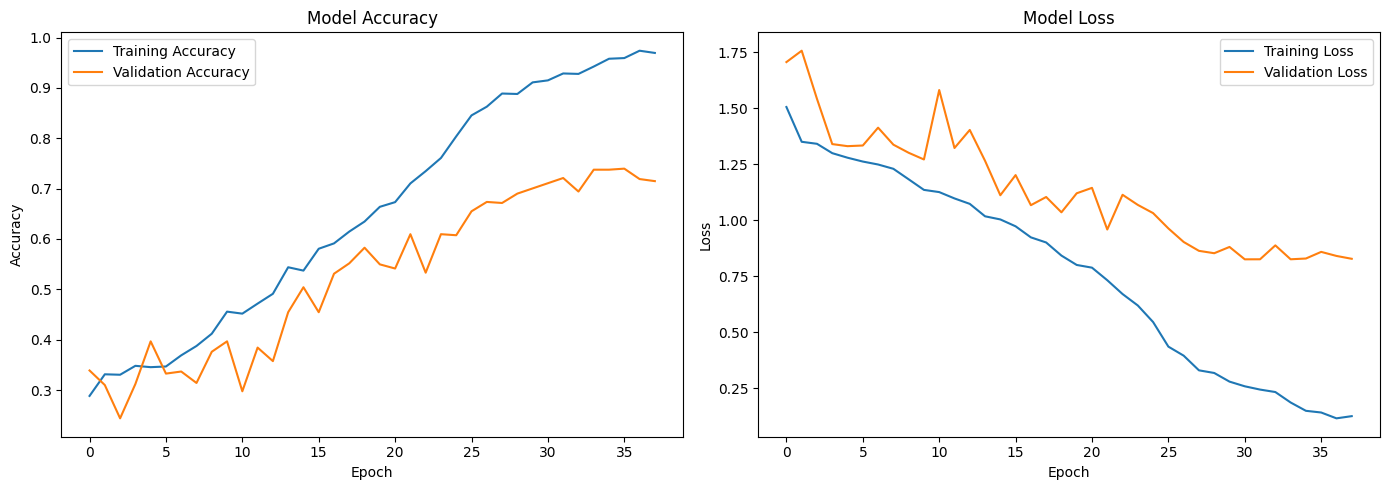

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [37]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.7169 - loss: 0.7862
Test Loss: 0.7862
Test Accuracy: 71.69%


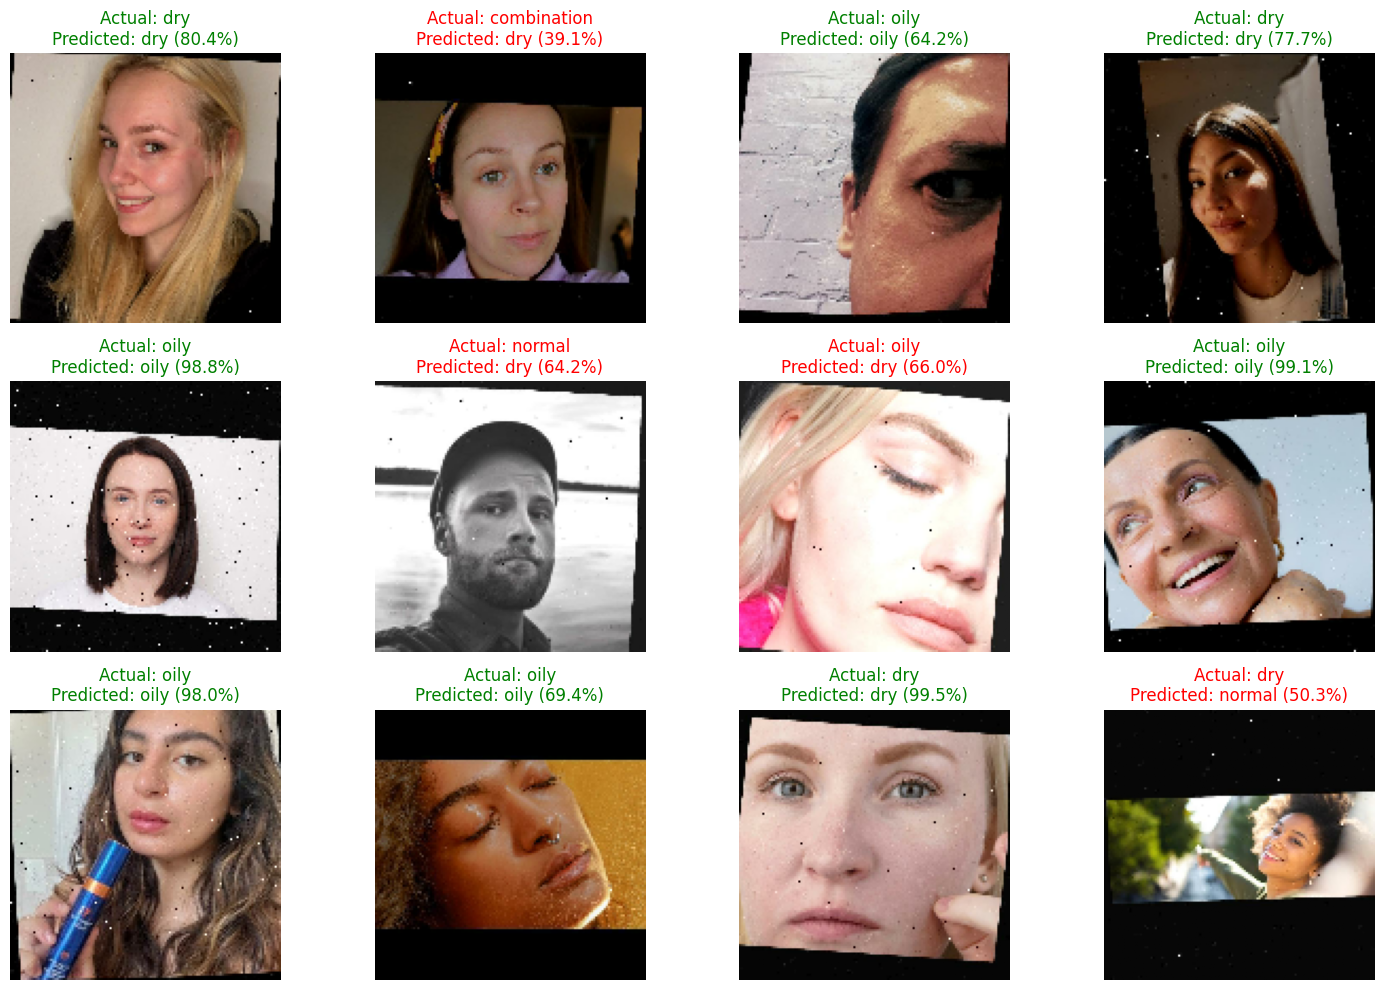

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Get one batch from the test dataset
images, labels = next(iter(test_ds))

# Predict
predictions = model.predict(images, verbose=0)

predicted_labels = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1)

# Display 12 images
plt.figure(figsize=(15, 10))

for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)

    actual = class_names[labels[i].numpy()]
    predicted = class_names[predicted_labels[i]]
    confidence = confidence_scores[i] * 100

    plt.imshow(images[i].numpy())

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted} ({confidence:.1f}%)",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
model.save("/content/skin_type_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [40]:
from google.colab import files

files.download("/content/skin_type_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>